# Demo: instruction, motion, replanning, outcome

Recorded rollouts of one SmolVLA checkpoint on LIBERO. Nothing here trains or rolls out the robot. The files were written earlier by `experiments/demos.py`.

Four instructions, the same initial state, three replanning intervals. `K` is how many of the 50 predicted actions run before the policy sees the scene again.

On each video the yellow line is the instruction. A red bar under it is a step where the policy was called again.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, Video, display

ROOT = Path("/mnt/d/RobotReplanStudy") if Path("/mnt/d/RobotReplanStudy").exists() else Path(r"D:/RobotReplanStudy")
EPISODES = ROOT / "results" / "episodes"
VIDEOS = ROOT / "results" / "videos"
TASKS = ("bowl_between", "table_center", "alphabet_soup", "soup_and_sauce")
HORIZONS = (1, 10, 50)

def load(name, k):
    stem = f"demo_{name}_init00_k{k:02d}"
    meta = json.loads((EPISODES / f"{stem}.json").read_text())
    trace = np.load(EPISODES / f"{stem}.npz")
    return meta, trace, VIDEOS / f"{stem}.mp4"

## The four instructions, at three intervals

In [2]:
print(f"{'instruction':62s} {'K':>4} {'result':8} {'steps':>6} {'calls':>6} {'misses':>6} {'slips':>5}")
for name in TASKS:
    for k in HORIZONS:
        meta, _, _ = load(name, k)
        result = "success" if meta["success"] else "failure"
        print(f"{meta['language']:62s} {k:4d} {result:8} {meta['steps']:6d} {meta['n_calls']:6d} {meta['n_miss']:6d} {meta['n_slip']:5d}")

instruction                                                       K result    steps  calls misses slips
pick up the black bowl between the plate and the ramekin and place it on the plate    1 success      76     76      0     0
pick up the black bowl between the plate and the ramekin and place it on the plate   10 failure     280     28     20     0
pick up the black bowl between the plate and the ramekin and place it on the plate   50 success      95      2      2     0
pick up the black bowl from table center and place it on the plate    1 failure     280    280     39     1
pick up the black bowl from table center and place it on the plate   10 failure     280     28     17     0
pick up the black bowl from table center and place it on the plate   50 failure     280      6      9     0
pick up the alphabet soup and place it in the basket              1 success     138    138      0     0
pick up the alphabet soup and place it in the basket             10 success     160     16      

## Watch one task

The plot under each video marks every step the policy was called. At K=1 that is every step. At K=50 it is once every 50 steps, until the episode ends.

**pick up the alphabet soup and place it in the basket**

K=1. success in 138 steps, 138 calls, 0 closes on nothing, 0 slips.

/tmp/ipykernel_463/3102257315.py:23: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


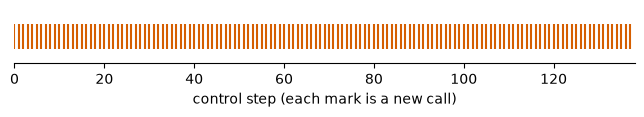

**pick up the alphabet soup and place it in the basket**

K=10. success in 160 steps, 16 calls, 0 closes on nothing, 0 slips.

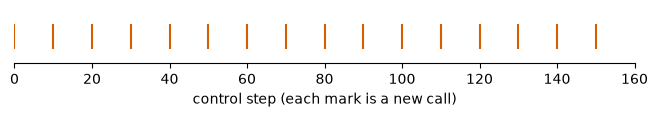

**pick up the alphabet soup and place it in the basket**

K=50. failure in 280 steps, 6 calls, 9 closes on nothing, 1 slips.

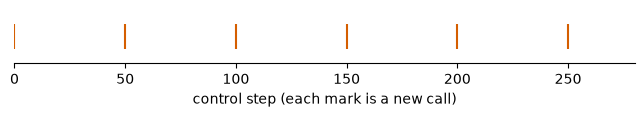

In [3]:
def show(name):
    for k in HORIZONS:
        meta, trace, video = load(name, k)
        result = "success" if meta["success"] else "failure"
        calls = np.flatnonzero(trace["replan"])
        display(Markdown(
            f"**{meta['language']}**\n\n"
            f"K={k}. {result} in {meta['steps']} steps, {meta['n_calls']} calls, "
            f"{meta['n_miss']} closes on nothing, {meta['n_slip']} slips."
        ))
        if video.exists():
            display(Video(filename=str(video), embed=True, width=420, html_attributes="controls"))
        else:
            print("no video at", video)
        fig, ax = plt.subplots(figsize=(8, 0.7))
        ax.eventplot(calls, colors="#D55E00", lineoffsets=0, linelengths=0.8)
        ax.set_xlim(0, meta["steps"])
        ax.set_yticks([])
        ax.set_xlabel("control step (each mark is a new call)")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_visible(False)
        fig.tight_layout()
        plt.show()

show("alphabet_soup")

### Why K=50 fails here and K=1 does not

Same start. Both horizons reach the can and close on it. At K=1 the next image arrives every step, so a slip is seen immediately and the can stays in the hand. At K=50 the call that closed on the can also committed the next 49 actions. The can falls back to the table inside that chunk, and the hand keeps the carry toward the basket. The following call sees an empty hand and closes on nothing. That is one slip and nine misses in the table above.

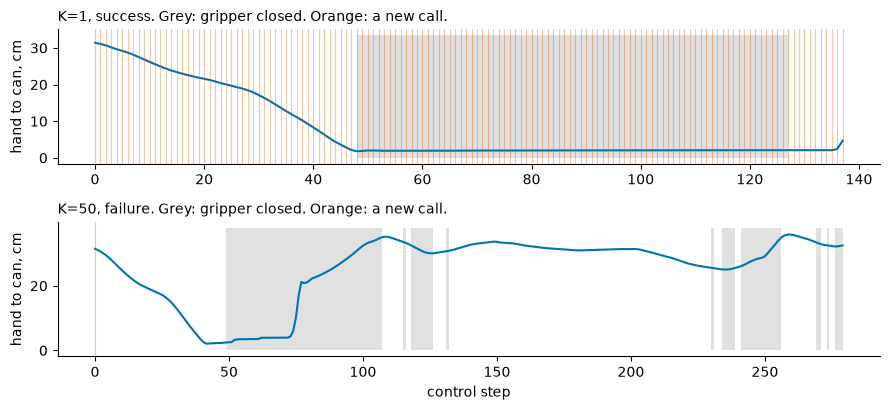

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(9, 4.2), sharex=False)
for ax, k in zip(axes, (1, 50)):
    meta, trace, _ = load("alphabet_soup", k)
    dist = np.linalg.norm(trace["target"][:, 0] - trace["eef"], axis=1) * 100
    steps = np.arange(len(dist))
    closed = trace["action"][:, -1] > 0
    ax.fill_between(steps, 0, dist.max() + 2, where=closed, color="#999999", alpha=0.3, linewidth=0)
    ax.plot(steps, dist, color="#0072B2")
    for t in np.flatnonzero(trace["replan"])[:: max(k, 1)]:
        ax.axvline(t, color="#D55E00", alpha=0.35, linewidth=0.8)
    word = "success" if meta["success"] else "failure"
    ax.set_title(f"K={k}, {word}. Grey: gripper closed. Orange: a new call.", loc="left", fontsize=10)
    ax.set_ylabel("hand to can, cm")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[1].set_xlabel("control step")
fig.tight_layout()
plt.show()

## The other three instructions

Bowl between the plate and the ramekin succeeds at K=1 and at K=50, and fails at K=10: the shorter interval is not uniformly safer. The hand never settles on the named bowl and closes on empty space (20 misses).

Table center fails at all three intervals on this start. The failures are empty closes, 39 of them at K=1, because three identical bowls have to be told apart on every new call and this start never locks onto the center one.

Soup and sauce is the opposite of the alphabet-soup clip. K=1 uses the whole step limit and fails: after placing the soup it goes back to that can and closes on it. K=10 and K=50 both finish. A fresh one-step plan never commits to the second grasp.

**pick up the black bowl between the plate and the ramekin and place it on the plate**

K=1. success in 76 steps, 76 calls, 0 closes on nothing, 0 slips.

/tmp/ipykernel_463/3102257315.py:23: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


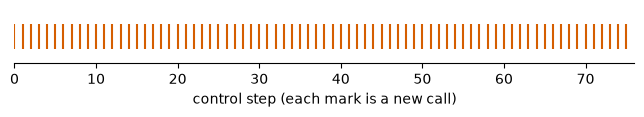

**pick up the black bowl between the plate and the ramekin and place it on the plate**

K=10. failure in 280 steps, 28 calls, 20 closes on nothing, 0 slips.

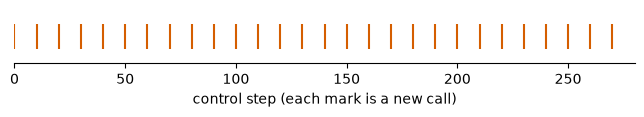

**pick up the black bowl between the plate and the ramekin and place it on the plate**

K=50. success in 95 steps, 2 calls, 2 closes on nothing, 0 slips.

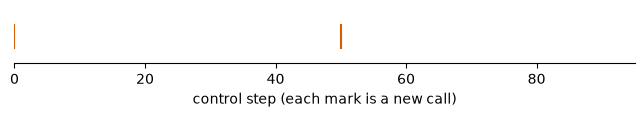

**pick up the black bowl from table center and place it on the plate**

K=1. failure in 280 steps, 280 calls, 39 closes on nothing, 1 slips.

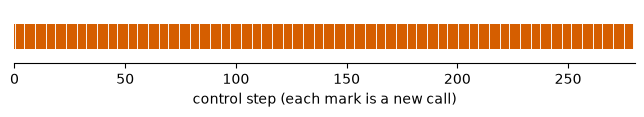

**pick up the black bowl from table center and place it on the plate**

K=10. failure in 280 steps, 28 calls, 17 closes on nothing, 0 slips.

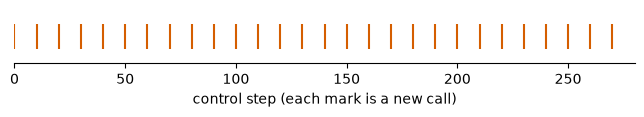

**pick up the black bowl from table center and place it on the plate**

K=50. failure in 280 steps, 6 calls, 9 closes on nothing, 0 slips.

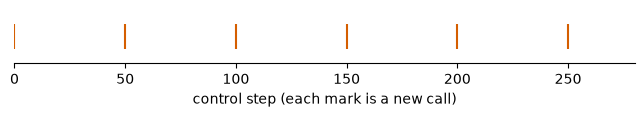

**put both the alphabet soup and the tomato sauce in the basket**

K=1. failure in 520 steps, 520 calls, 33 closes on nothing, 1 slips.

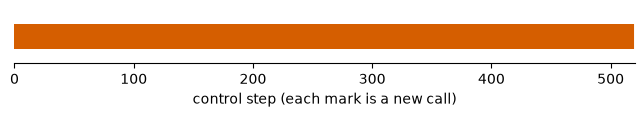

**put both the alphabet soup and the tomato sauce in the basket**

K=10. success in 283 steps, 29 calls, 0 closes on nothing, 0 slips.

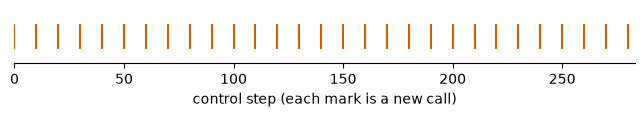

**put both the alphabet soup and the tomato sauce in the basket**

K=50. success in 414 steps, 9 calls, 5 closes on nothing, 0 slips.

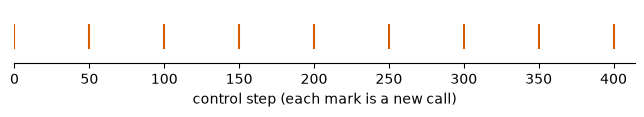

In [5]:
show("bowl_between")
show("table_center")
show("soup_and_sauce")

### Soup and sauce: the hand's distance to each can

K=1 reaches the sauce and then leaves it. K=10 stays with the second can long enough to finish.

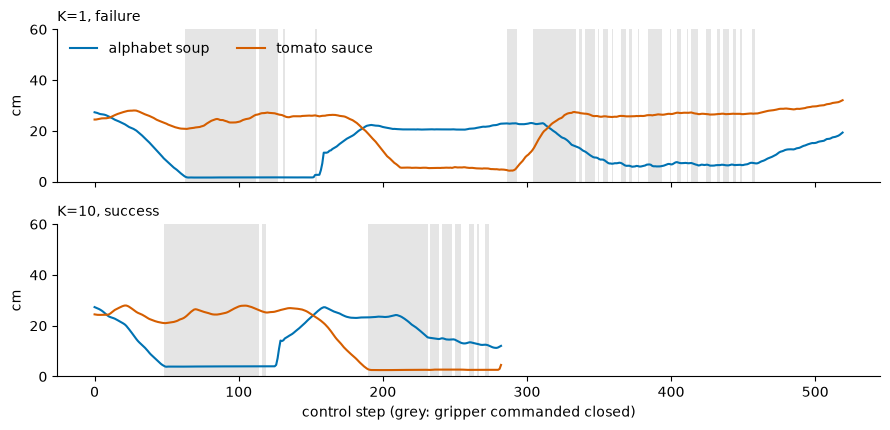

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(9, 4.4), sharex=True)
for ax, k in zip(axes, (1, 10)):
    meta, trace, _ = load("soup_and_sauce", k)
    dist = np.linalg.norm(trace["target"] - trace["eef"][:, None, :], axis=2) * 100
    steps = np.arange(len(dist))
    closed = trace["action"][:, -1] > 0
    ax.fill_between(steps, 0, 60, where=closed, color="#999999", alpha=0.25, linewidth=0)
    ax.plot(steps, dist[:, 0], color="#0072B2", label="alphabet soup")
    ax.plot(steps, dist[:, 1], color="#D55E00", label="tomato sauce")
    word = "success" if meta["success"] else "failure"
    ax.set_title(f"K={k}, {word}", loc="left", fontsize=10)
    ax.set_ylim(0, 60)
    ax.set_ylabel("cm")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[0].legend(frameon=False, ncol=2)
axes[1].set_xlabel("control step (grey: gripper commanded closed)")
fig.tight_layout()
plt.show()